# Billix POS — Recommendation-System EDA

## Goal
Validate the POS data and answer one question: **is it suitable for a basket-based recommendation system?**

Interview flow: **validate data → define baskets → establish a popularity baseline → inspect co-occurrence → create the model matrix → state limitations.**

## 1. Load the two tables
`transactions.csv` has one row per sale. `transaction_items.csv` contains the products in each sale and is the main input for market-basket recommendation.

In [1]:
from itertools import combinations
from pathlib import Path
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

sns.set_theme(style="whitegrid")
DATA_DIR = Path("../data/processed")
transactions = pd.read_csv(DATA_DIR / "transactions.csv", parse_dates=["occurred_at"])
items = pd.read_csv(DATA_DIR / "transaction_items.csv", parse_dates=["occurred_at"])

print(f"Transactions: {len(transactions):,}")
print(f"Item rows: {len(items):,}")
display(transactions.head(3), items.head(3))

Transactions: 514
Item rows: 1,029


,transaction_id,store_id,branch_id,occurred_at,payment_type,total_amount
0,1839,1,1,2026-10-11 09:57:00,UPI,8498.0
1,1807,1,1,2026-10-11 10:23:00,UPI,1248.0
2,2133,1,1,2026-10-11 11:01:00,CASH,9498.0


,transaction_id,store_id,branch_id,occurred_at,product_id,product_sku,product_name,category_id,category_name,quantity,unit_price,line_total
0,1839,1,1,2026-10-11 09:57:00,7,ELEC-KB-007,RGB Mechanical Gaming Keyboard,1,Electronics,1,3499.0,3499.0
1,1839,1,1,2026-10-11 09:57:00,1,ELEC-HD-001,Wireless Noise-Canceling Headphones,1,Electronics,1,4999.0,4999.0
2,1807,1,1,2026-10-11 10:23:00,3,BEV-CF-003,Organic Arabica Coffee Beans 500g,2,Beverages & Snacks,1,749.0,749.0


## 2. Validate data quality
Bad rows create bad baskets. Check missing data, duplicates, invalid values, orphan items, and monetary consistency before modelling.

In [2]:
item_totals = items.groupby("transaction_id")["line_total"].sum()
recorded_totals = transactions.set_index("transaction_id")["total_amount"]
common_ids = recorded_totals.index.intersection(item_totals.index)

checks = {
    "no missing values": transactions.isna().sum().sum() + items.isna().sum().sum() == 0,
    "transaction IDs are unique": transactions["transaction_id"].is_unique,
    "no duplicate item rows": not items.duplicated().any(),
    "no orphan item transactions": set(items["transaction_id"]) <= set(transactions["transaction_id"]),
    "positive quantities": items["quantity"].gt(0).all(),
    "non-negative prices": items["unit_price"].ge(0).all(),
    "line totals are correct": (items["line_total"] - items["quantity"] * items["unit_price"]).abs().le(0.01).all(),
    "transaction totals match items": (recorded_totals.loc[common_ids] - item_totals.loc[common_ids]).abs().le(0.01).all(),
}
quality_report = pd.Series(checks, name="passed").rename_axis("check").reset_index()
display(quality_report)
assert quality_report["passed"].all(), "Fix failed checks before modelling."

,check,passed
0,no missing values,True
1,transaction IDs are unique,True
2,no duplicate item rows,True
3,no orphan item transactions,True
4,positive quantities,True
5,non-negative prices,True
6,line totals are correct,True
7,transaction totals match items,True


## 3. Define and understand baskets
A **basket** is the set of unique products in one completed transaction. Repeated units should not create repeated co-occurrences.

In [3]:
baskets = items.groupby("transaction_id")["product_id"].agg(lambda values: sorted(set(values)))
basket_sizes = baskets.str.len()
summary = pd.Series({
    "transactions": transactions["transaction_id"].nunique(),
    "products": items["product_id"].nunique(),
    "categories": items["category_id"].nunique(),
    "average unique products per basket": basket_sizes.mean(),
    "multi-product baskets (%)": basket_sizes.gt(1).mean() * 100,
    "date range (days)": (transactions["occurred_at"].max() - transactions["occurred_at"].min()).days + 1,
})
display(summary.to_frame("value"))
display(baskets.head())

,value
transactions,514.000000
products,11.000000
categories,5.000000
average unique products per basket,2.001946
multi-product baskets (%),88.910506
date range (days),30.000000


transaction_id
152    [1]
153    [2]
154    [3]
155    [7]
156    [5]
Name: product_id, dtype: object

## 4. Popularity baseline
The simplest recommender returns popular products. It is the baseline a learned model should beat and a useful fallback for an empty cart or unmatched basket. **Support** is the fraction of baskets containing a product.

,product_id,product_name,basket_count,units_sold,support
0,1,Wireless Noise-Canceling Headphones,183,202,0.356031
8,9,Gourmet Dark Chocolate Truffles 250g,162,173,0.315175
2,3,Organic Arabica Coffee Beans 500g,159,181,0.309339
6,7,RGB Mechanical Gaming Keyboard,130,142,0.252918
4,5,Stainless Steel Water Flask 1L,121,134,0.235409
7,8,Smart Fitness Tracker Watch,84,90,0.163424
1,2,Smart HD LED Television 43-inch,60,65,0.116732
3,4,Premium Denim Jacket,49,52,0.095331
9,10,Full Grain Leather Travel Duffle Bag,49,56,0.095331
5,6,Ergonomic Mesh Office Chair,31,33,0.060311


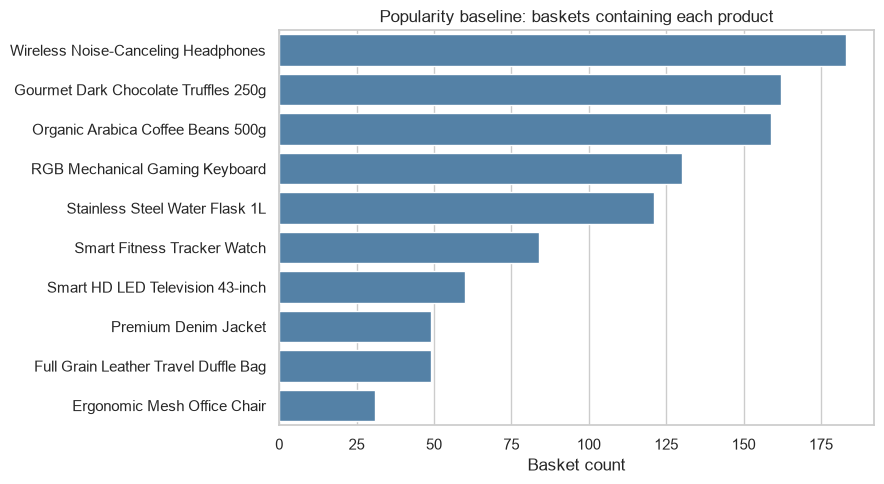

In [4]:
total_baskets = baskets.size
popularity = (items.groupby(["product_id", "product_name"])
              .agg(basket_count=("transaction_id", "nunique"), units_sold=("quantity", "sum"))
              .reset_index())
popularity["support"] = popularity["basket_count"] / total_baskets
popularity = popularity.sort_values("basket_count", ascending=False)
display(popularity.head(10))

plt.figure(figsize=(9, 5))
sns.barplot(data=popularity.head(10), x="basket_count", y="product_name", color="steelblue")
plt.title("Popularity baseline: baskets containing each product")
plt.xlabel("Basket count"); plt.ylabel(""); plt.tight_layout(); plt.show()

## 5. Product co-occurrence
Co-occurrence counts how often two products share a basket. It shows learnable relationships but is **not yet a model**; confidence and lift are added during association-rule training.

In [5]:
names = items.drop_duplicates("product_id").set_index("product_id")["product_name"]
pair_counts = {}
for basket in baskets:
    for pair in combinations(basket, 2):
        pair_counts[pair] = pair_counts.get(pair, 0) + 1

pairs = pd.DataFrame([
    {"product_a": names.loc[a], "product_b": names.loc[b],
     "basket_count": count, "pair_support": count / total_baskets}
    for (a, b), count in pair_counts.items()
]).sort_values("basket_count", ascending=False)
display(pairs.head(10))

,product_a,product_b,basket_count,pair_support
4,Organic Arabica Coffee Beans 500g,Gourmet Dark Chocolate Truffles 250g,150,0.291829
3,Wireless Noise-Canceling Headphones,RGB Mechanical Gaming Keyboard,126,0.245136
5,Stainless Steel Water Flask 1L,Smart Fitness Tracker Watch,79,0.153696
6,Wireless Noise-Canceling Headphones,Smart HD LED Television 43-inch,54,0.105058
9,Premium Denim Jacket,Full Grain Leather Travel Duffle Bag,45,0.087549
10,Organic Arabica Coffee Beans 500g,Stainless Steel Water Flask 1L,34,0.066148
11,Stainless Steel Water Flask 1L,Gourmet Dark Chocolate Truffles 250g,34,0.066148
7,Wireless Noise-Canceling Headphones,Ergonomic Mesh Office Chair,24,0.046693
8,Ergonomic Mesh Office Chair,RGB Mechanical Gaming Keyboard,24,0.046693
0,RGB Mechanical Gaming Keyboard,Smart Fitness Tracker Watch,1,0.001946


## 6. Transaction–product matrix
Rows are transactions, columns are products, and `True` means present. FP-Growth/Apriori uses this representation. **Sparsity** is the percentage of absent interactions and is normal in recommender data.

In [6]:
basket_matrix = pd.crosstab(items["transaction_id"], items["product_id"]).gt(0)
density = basket_matrix.to_numpy().mean()
print(f"Matrix shape: {basket_matrix.shape}")
print(f"Density: {density:.2%}")
print(f"Sparsity: {1 - density:.2%}")
display(basket_matrix.head())

Matrix shape: (514, 11)
Density: 18.20%
Sparsity: 81.80%


product_id,1,2,3,4,5,6,7,8,9,10,102
transaction_id,,,,,,,,,,,
152,True,False,False,False,False,False,False,False,False,False,False
153,False,True,False,False,False,False,False,False,False,False,False
154,False,False,True,False,False,False,False,False,False,False,False
155,False,False,False,False,False,False,True,False,False,False,False
156,False,False,False,False,True,False,False,False,False,False,False


## 7. Interview-ready conclusion

### Decision
The data passes integrity checks, contains multi-product baskets, and has repeated co-occurrence. It supports an **association-rule recommender**, with popularity as the cold-start fallback.

### Metrics to know
- **Support:** fraction of all baskets containing an item/itemset.
- **Confidence A → B:** among baskets containing A, the fraction also containing B.
- **Lift A → B:** confidence divided by B's overall support; lift greater than 1 suggests positive association.
- **Sparsity:** fraction of missing transaction–product interactions.

### Honest limitations
- Most data is synthetic: it demonstrates engineering and modelling, not real customer behaviour.
- Only 11 products, one store, one branch, and about 30 days are represented.
- No customer identity is exported, so this is basket-based—not personalized collaborative filtering.
- Offline evaluation and production feedback (shown, clicked, purchased) are still needed.

### Next step
Move basket preparation into reusable tested Python code, then train and evaluate association rules.